# Deliverable 1 
## Thea Ariansen Gathe, Kiki Julia Titia Beumer

Import libraries

In [85]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### Task 1: Temperature

Retrieve the user ID and secret of frost.met.no\
The format of the txt file should look as follows:\
*user: <user_ID>\
secret: <secret_code>*



In [86]:
# Get the user ID and secret from txt file 
with open("secret.txt") as f:
    user_id = f.readline().split(":", 1)[1].strip()
    secret = f.readline().split(":", 1)[1].strip()

print(user_id)
print(secret)

5cda23a3-ca3a-42c6-9207-a151bec2f398
96f282a9-b316-4b35-b24c-6692c82721e5


Define the parameters, request, and store in json file 

In [87]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(user_id, secret))

# Extract JSON data
json_df = r.json()

Check if the request worked, print out any errors

In [88]:
if r.status_code == 200:
    data = json_df['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json_df['error']['message'])
    print('Reason: %s' % json_df['error']['reason'])

Data retrieved from frost.met.no!


Create the dataframe

In [89]:
df = pd.DataFrame()
rows = []

for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)

df = pd.concat(rows, ignore_index=True)

df = df.reset_index()
df.head()

,index,elementId,value,unit,level,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,0,mean(air_temperature P1D),-5.2,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,0.0,2025-01-01T00:00:00.000Z,SN17850:0
1,1,mean(air_temperature P1D),-2.8,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT6H,P1D,0,C,1,NaN,2025-01-01T00:00:00.000Z,SN17850:0
2,2,mean(air_temperature P1D),-11.5,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,0.0,2025-01-02T00:00:00.000Z,SN17850:0
3,3,mean(air_temperature P1D),-7.2,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT6H,P1D,0,C,1,NaN,2025-01-02T00:00:00.000Z,SN17850:0
4,4,mean(air_temperature P1D),-8.9,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,0.0,2025-01-03T00:00:00.000Z,SN17850:0


Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis

In [90]:
# Ensure that time is in proper format
df['referenceTime'] = pd.to_datetime(df['referenceTime'])

df.dtypes

index                                int64
elementId                           object
value                              float64
unit                                object
level                               object
timeOffset                          object
timeResolution                      object
timeSeriesId                         int64
performanceCategory                 object
exposureCategory                    object
qualityCode                        float64
referenceTime          datetime64[ns, UTC]
sourceId                            object
dtype: object

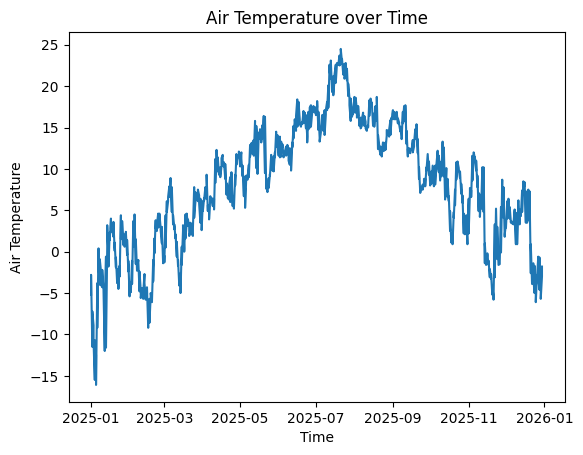

In [91]:
x = df['referenceTime']
y = df['value']

fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_title("Air Temperature over Time")
ax.set_xlabel("Time")
ax.set_ylabel("Air Temperature")

plt.show()

Create a nicely formatted summary table containing mean, median, min and max temperature for this year

In [92]:
df['value'].describe()

count    728.000000
mean       7.903571
std        7.528326
min      -16.100000
25%        2.800000
50%        8.350000
75%       13.800000
max       24.500000
Name: value, dtype: float64

### Task 2: Precipitation

Request data for precipitation for the same time period, specifically measurements
of precipitation over 24 hours. 

In [93]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r2 = requests.get(endpoint, parameters, auth=(user_id, secret))

# Extract JSON data
json_df2 = r2.json()

Check if the request worked, print out any errors

In [94]:
if r2.status_code == 200:
    data2 = json_df2['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r2.status_code)
    print('Message: %s' % json_df2['error']['message'])
    print('Reason: %s' % json_df2['error']['reason'])

Data retrieved from frost.met.no!


Create the dataframe

In [95]:
df2 = pd.DataFrame()
rows2 = []

for i in range(len(data2)):
    row2 = pd.DataFrame(data2[i]['observations'])
    row2['referenceTime'] = data2[i]['referenceTime']
    row2['sourceId'] = data2[i]['sourceId']
    rows2.append(row2)

df2 = pd.concat(rows2, ignore_index=True)

df2 = df2.reset_index()
df2.head()

,index,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,0,sum(precipitation_amount P1D),5.4,mm,PT18H,P1D,0,C,2,NaN,2025-01-01T00:00:00.000Z,SN17850:0
1,1,sum(precipitation_amount P1D),6.6,mm,PT6H,P1D,0,C,2,0.0,2025-01-01T00:00:00.000Z,SN17850:0
2,2,sum(precipitation_amount P1D),0.0,mm,PT18H,P1D,0,C,2,NaN,2025-01-02T00:00:00.000Z,SN17850:0
3,3,sum(precipitation_amount P1D),1.9,mm,PT6H,P1D,0,C,2,0.0,2025-01-02T00:00:00.000Z,SN17850:0
4,4,sum(precipitation_amount P1D),0.1,mm,PT18H,P1D,0,C,2,NaN,2025-01-03T00:00:00.000Z,SN17850:0


In [96]:
# Ensure that time is in proper format
df2['referenceTime'] = pd.to_datetime(df2['referenceTime'])

df2.dtypes

index                                int64
elementId                           object
value                              float64
unit                                object
timeOffset                          object
timeResolution                      object
timeSeriesId                         int64
performanceCategory                 object
exposureCategory                    object
qualityCode                        float64
referenceTime          datetime64[ns, UTC]
sourceId                            object
dtype: object

Temperature is continuous, so a line would be appropriate. Precipitation is accumulated over a day, so bars would be best.

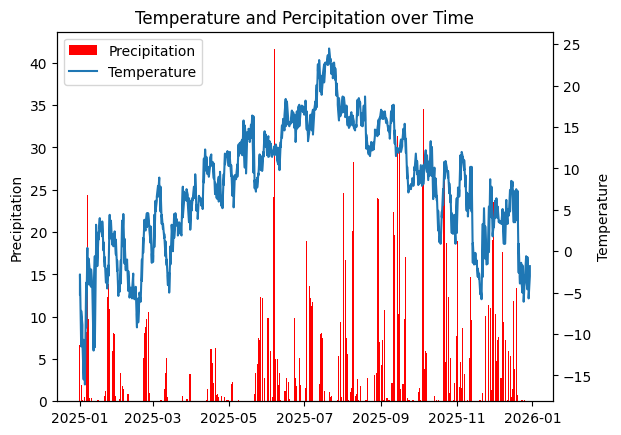

In [97]:
fig, ax1 = plt.subplots()

# Bar plot
ax1.bar(df2['referenceTime'], df2['value'], color = 'red', label='Precipitation')
ax1.set_ylabel('Precipitation')

# Line plot
ax2 = ax1.twinx()
ax2.plot(df['referenceTime'], df['value'], label='Temperature')
ax2.set_ylabel('Temperature')

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')

plt.title('Temperature and Percipitation over Time')
plt.show()


### Task 3: Historical temperature data

Get the temperatures from 100 years ago

In [98]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '1925-01-01/1925-12-31',
}

# Issue an HTTP GET request
r3 = requests.get(endpoint, parameters, auth=(user_id, secret))

# Extract JSON data
json_df3 = r3.json()

# Check if request worked
if r3.status_code == 200:
    data3 = json_df3['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r3.status_code)
    print('Message: %s' % json_df3['error']['message'])
    print('Reason: %s' % json_df3['error']['reason'])

Data retrieved from frost.met.no!


Create the dataframe

In [99]:
df3 = pd.DataFrame()
rows3 = []

for i in range(len(data3)):
    row3 = pd.DataFrame(data3[i]['observations'])
    row3['referenceTime'] = data3[i]['referenceTime']
    row3['sourceId'] = data3[i]['sourceId']
    rows3.append(row3)

df3 = pd.concat(rows3, ignore_index=True)

df3 = df3.reset_index()
df3.head()

,index,elementId,value,unit,level,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId
0,0,mean(air_temperature P1D),1.3,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-01T00:00:00.000Z,SN17850:0
1,1,mean(air_temperature P1D),4.1,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-02T00:00:00.000Z,SN17850:0
2,2,mean(air_temperature P1D),2.1,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-03T00:00:00.000Z,SN17850:0
3,3,mean(air_temperature P1D),0.1,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-04T00:00:00.000Z,SN17850:0
4,4,mean(air_temperature P1D),-2.2,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-05T00:00:00.000Z,SN17850:0


In [100]:
# Ensure that time is in proper format
df3['referenceTime'] = pd.to_datetime(df3['referenceTime'])

df3.dtypes

index                                int64
elementId                           object
value                              float64
unit                                object
level                               object
timeOffset                          object
timeResolution                      object
timeSeriesId                         int64
performanceCategory                 object
exposureCategory                    object
qualityCode                          int64
referenceTime          datetime64[ns, UTC]
sourceId                            object
dtype: object

Add day and month as column in df and df3

In [101]:
# Remove the year from the datetime
df['month_day'] = df['referenceTime'].dt.strftime('%m-%d')
df3['month_day'] = df3['referenceTime'].dt.strftime('%m-%d')

df3.head(5)

,index,elementId,value,unit,level,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,referenceTime,sourceId,month_day
0,0,mean(air_temperature P1D),1.3,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-01 00:00:00+00:00,SN17850:0,01-01
1,1,mean(air_temperature P1D),4.1,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-02 00:00:00+00:00,SN17850:0,01-02
2,2,mean(air_temperature P1D),2.1,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-03 00:00:00+00:00,SN17850:0,01-03
3,3,mean(air_temperature P1D),0.1,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-04 00:00:00+00:00,SN17850:0,01-04
4,4,mean(air_temperature P1D),-2.2,degC,"{'levelType': 'height_above_ground', 'unit': '...",PT0H,P1D,0,C,1,2,1925-01-05 00:00:00+00:00,SN17850:0,01-05


In [102]:
df3.dtypes

index                                int64
elementId                           object
value                              float64
unit                                object
level                               object
timeOffset                          object
timeResolution                      object
timeSeriesId                         int64
performanceCategory                 object
exposureCategory                    object
qualityCode                          int64
referenceTime          datetime64[ns, UTC]
sourceId                            object
month_day                           object
dtype: object

Plot the new and the old temperatures in the same plot

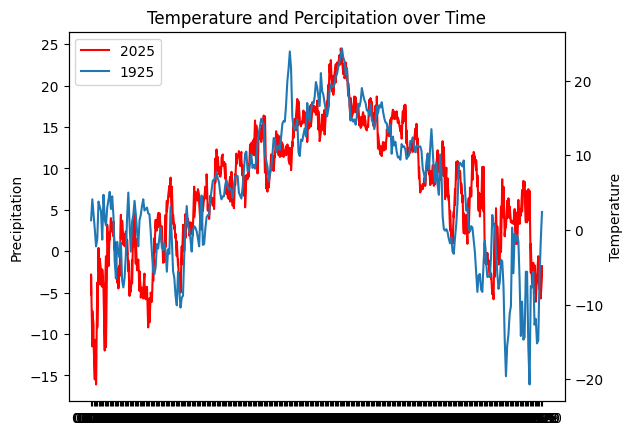

In [103]:
fig, ax1 = plt.subplots()

# Bar plot
ax1.plot(df['month_day'], df['value'], color = 'red', label='2025')
ax1.set_ylabel('Precipitation')

# Line plot
ax2 = ax1.twinx()
ax2.plot(df3['month_day'], df3['value'], label='1925')
ax2.set_ylabel('Temperature')

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')

plt.title('Temperature and Percipitation over Time')

plt.show()


Generate a summary table as for task 1, where you display data from both the new
and the old temperatures

### Task 4: Heatwaves

### Task 5: Moving average temperature

### References:
* https://frost.met.no/python_example.html
* https://stackoverflow.com/questions/37930693/how-can-i-make-a-barplot-and-a-lineplot-in-the-same-plot-with-different-y-axes